# Final checks

Collection of robustness checks for the paper. Sections:

1. **Aliasing in the bias-field pipeline** (operator construction + CIC deposit)
2. **Phase-matched muchisimocks vs. SHAMe** (cosmic-variance-free comparison)

In [1]:
import sys
from pathlib import Path

try:
    REPO_ROOT = Path(__file__).resolve().parents[1]
except NameError:
    REPO_ROOT = Path.cwd()
    if REPO_ROOT.name == "notebooks":
        REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT / "code"))
sys.path.insert(0, str(REPO_ROOT / "code_auxiliary"))

import numpy as np
from matplotlib import pyplot as plt

import paths

%load_ext autoreload
%autoreload 2

## 1. Aliasing in the bias-field pipeline

Two places aliasing could enter `data_creation_pipeline.predicted_positions_to_bias_fields` (box $L=1000\,h^{-1}$Mpc):

**(a) Building the Lagrangian operators** $\{1, \delta, \delta^2, s^2, \nabla^2\delta\}$ on the $512^3$ grid ($k_N = \pi\cdot512/L = 1.61\,h$/Mpc). Products of fields generate modes up to the sum of their wavenumbers, which can wrap past $k_N$ (Orszag 2/3 rule). The linear field is smoothed with `damping_scale=0.75`, which in bacco is a near-sharp cut, $P(k)\to P(k)\cdot\tfrac12\,\mathrm{erfc}[\log_{10}(k/0.75)/0.01]$ (`lss_scaler/lssmodule.c`), ~2% wide in $k$. So $\delta$ has no power above $0.75$, the quadratic operators reach at most $1.5 < k_N$, and **nothing wraps at all** (stronger than the 2/3 condition $0.75 < 1.07$). Any wrapping would in any case land at $k \geq 2k_N - 1.5 = 1.72$, far above our $k$-cut at $0.40$. → No test needed; argued analytically.

**(b) The Eulerian CIC deposit** of the $512^3$ weighted particles at the nonlinear map2map positions. This is *not* band-limited, so CIC aliases power from $k > k_N$ into our band, and dividing by the CIC window (the deconvolution) cannot remove that.

**Test** (`code/test_deposit_aliasing.py`, run on `muchisimocks_lib_p5_n10000_rerun/LH0`, the one mock with `pred_disp.npy` saved): keep the particles and Lagrangian weights fixed, vary only the deposit mesh, then $k$-cut to $128^3$ and deconvolve with the matching grid, exactly as the pipeline does. Reference: $1024^3$ ($k_N = 3.2$).

| config | deposit mesh | $k_N$ [$h$/Mpc] |
|---|---|---|
| `ng256` | $256^3$ | 0.80 |
| `ng512` | $512^3$ (production) | 1.61 |
| `ng512i` | $512^3$, interlaced | 1.61 |
| `ng1024` | $1024^3$ (reference) | 3.22 |

Built-in checks: regenerated linear field matches the saved one exactly; `ng512` reproduces the production `bias_fields_eul_deconvolved_0.npy` to $\sim10^{-14}$.

Caveat: one mock, LH0, with fairly low $\sigma_8 = 0.70$; higher-$\sigma_8$ cosmologies have more small-scale power and will alias somewhat more.

In [2]:
dir_alias = paths.DIR_DATA / "aliasing_test" / "LH0"
res = dict(np.load(dir_alias / "summary.npz"))
k = res["k"]

ops = ["1", "delta", "delta2", "s2", "nabla2delta"]
op_labels = {"tracer": "tracer", "1": r"$1$", "delta": r"$\delta$", "delta2": r"$\delta^2$",
             "s2": r"$s^2$", "nabla2delta": r"$\nabla^2\delta$"}
cfgs = ["ng256", "ng512", "ng512i"]
cfg_labels = {"ng256": r"$256^3$", "ng512": r"$512^3$ (production)", "ng512i": r"$512^3$ interlaced"}
cfg_colors = {"ng256": "C3", "ng512": "C0", "ng512i": "C2"}
ref = "ng1024"
kmax_analysis = 0.35

# Gaussian per-bin statistical error on P(k) for one (1 Gpc/h)^3 box, for scale
kf = 2 * np.pi / 1000.
dk = np.median(np.diff(k))
sigma_frac = np.sqrt(2 / (4 * np.pi * k**2 * dk / kf**3))

In [3]:
# Summary table: max |P/P_ref - 1| over k <= kmax_analysis
m = k <= kmax_analysis
print(f"max |P/P_ref - 1| for k <= {kmax_analysis} (ref = {ref})")
print(f"{'':<14s}" + "".join(f"{c:>12s}" for c in cfgs))
for op in ["tracer"] + ops:
    vals = [np.abs(res[f"pk_{op}_{c}"][m] / res[f"pk_{op}_{ref}"][m] - 1).max() for c in cfgs]
    print(f"{op:<14s}" + "".join(f"{v:12.1e}" for v in vals))
print(f"{'stat. error':<14s}{sigma_frac[m].min():12.1e}  (smallest per-bin Gaussian error, at k={k[m][-1]:.2f})")
print("\nproduction vs ng512 (tracer, field-level):", res["pdiff_tracer_production_vs_ng512"][m].max())

max |P/P_ref - 1| for k <= 0.35 (ref = ng1024)
                     ng256       ng512      ng512i
tracer             8.0e-04     6.8e-05     4.2e-07
1                  5.6e-04     4.8e-05     4.2e-07
delta              8.7e-04     8.8e-05     4.3e-07
delta2             1.6e-03     2.1e-04     4.2e-07
s2                 8.4e-04     8.3e-05     4.2e-07
nabla2delta        2.6e-03     1.4e-04     4.1e-07
stat. error        5.1e-03  (smallest per-bin Gaussian error, at k=0.35)

production vs ng512 (tracer, field-level): 4.026352822988555e-14


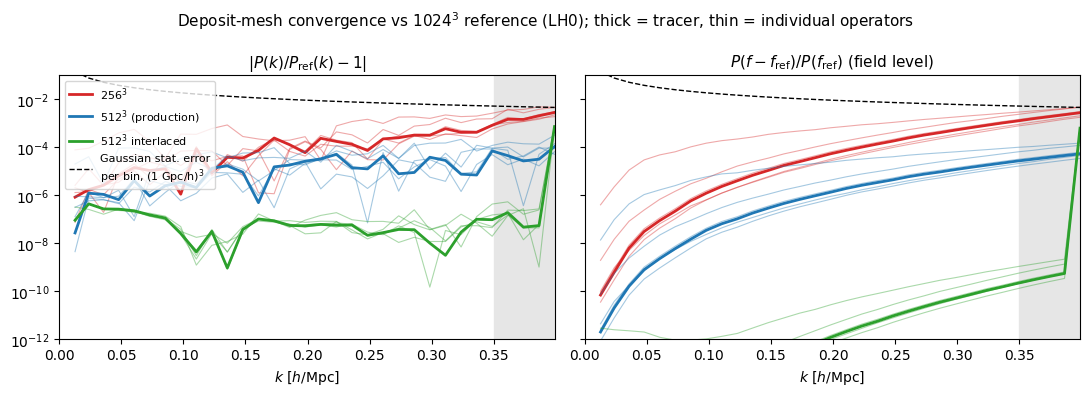

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, kind, title in zip(axes, ["pk", "pdiff"],
                           [r"$|P(k)/P_\mathrm{ref}(k) - 1|$",
                            r"$P(f - f_\mathrm{ref})/P(f_\mathrm{ref})$ (field level)"]):
    for c in cfgs:
        for op in ["tracer"] + ops:
            if kind == "pk":
                y = np.abs(res[f"pk_{op}_{c}"] / res[f"pk_{op}_{ref}"] - 1)
            else:
                y = res[f"pdiff_{op}_{c}"] / res[f"pk_{op}_{ref}"]
            is_tr = op == "tracer"
            ax.plot(k, y, color=cfg_colors[c], lw=2 if is_tr else 0.8, alpha=1 if is_tr else 0.4,
                    label=cfg_labels[c] if is_tr else None)
    ax.plot(k, sigma_frac, "k--", lw=1, label="Gaussian stat. error\nper bin, (1 Gpc/h)$^3$")
    ax.axvspan(kmax_analysis, k.max(), color="0.9", zorder=0)
    ax.set_yscale("log")
    ax.set_xlabel(r"$k$ [$h$/Mpc]")
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, k.max())
axes[0].set_ylim(1e-12, 1e-1)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(rf"Deposit-mesh convergence vs $1024^3$ reference (LH0); thick = tracer, thin = individual operators", fontsize=11)
fig.tight_layout()
plt.show()

**Conclusion.** Relative to the $1024^3$ reference, the production $512^3$ deposit changes $P(k)$ of the tracer and of every operator by $\lesssim 2\times10^{-4}$ for $k \le 0.35\,h$/Mpc (tracer: $7\times10^{-5}$ at $k=0.35$), about two orders of magnitude below the per-bin statistical error of a single box ($\sim 0.5\%$). The test is sensitive: $256^3$ is ~10× worse and grows with $k$ as expected for aliasing. The $1024^3$ and interlaced-$512^3$ results, two independent anti-aliasing methods, agree to $\sim10^{-7}$, so the reference is converged and the $\sim10^{-4}$ residual in production really is aliasing. The CIC window itself differs by a few percent between $512^3$ and $1024^3$ at $k = 0.35$, yet the deconvolved fields agree to $\sim10^{-4}$, so the deconvolution is exact up to aliasing. (The $-7\times10^{-4}$ in `ng512i` at $k\approx0.40$ is an artifact of combining the interlaced grids on the $128^3$ Nyquist planes, beyond our $k$ range.)

*Paper text:* "We verified that depositing onto a $1024^3$ mesh changes the $k$-cut, deconvolved operator fields by at most $2\times10^{-4}$ in $P(k)$ for $k \le 0.35\,h\,\mathrm{Mpc}^{-1}$, so aliasing in the deposit step is negligible.\"

## 2. Phase-matched muchisimocks vs. SHAMe

The SHAMe high-fidelity mock lives on the BACCO "Rings" paired-and-fixed run (Planck, $L=1024\,h^{-1}$Mpc, $3072^3$, phases $0$ and $\pi$). Using the Rings seed **$-406168$** (verified with `make_shame_matched_mock.py check_seed`: the $132^3$ linear field correlates with the SHAMe $z=0$ matter mesh at $r>0.98$ for $k<0.05$, both phases; seed $0$ gives $r\approx0$), we regenerated the muchisimocks bias-operator fields with **identical initial conditions**: `make_shame_matched_mock.py make --seed -406168` (box 1024, $524^3 \to 132^3$, fixed amplitude, `phase_type=1`). Output: `muchisimocks_lib_ood/shame_matched/phase{0,pi}_seed-406168/`.

Because both share the same phases, differences are free of sample variance and can be compared mode by mode. Real space throughout (the SHAMe meshes are real space). Checks:

- **(a) Matter:** map2map $O_1 = 1+\delta_m$ vs. the N-body matter mesh.
- **(b) Tracer, deterministic part:** $\delta_t^\mathrm{model} = \delta_m + b_1\delta + b_2\delta^2 + b_{s^2}s^2 + b_{\nabla^2}\nabla^2\delta$ with (i) the fiducial SHAMe biases `utils_model.bias_dict_shame` and (ii) biases fit at field level to each SHAMe catalog ($k\le0.2$, least squares over modes), compared with $P_\mathrm{SHAMe} - 1/\bar n$.
- **(c) Stochasticity:** $P_\mathrm{err}(k) = P(\delta_\mathrm{SHAMe} - \delta_t^\mathrm{model})$ in units of Poisson $1/\bar n$; this is what our noise model has to describe.

P(k) here is a plain numpy FFT estimator with $\Delta k = k_f$ (so auto, cross and residual spectra are binned identically); it agrees with the stored bacco SHAMe $P(k)$ to $<1\%$ except in the first couple of (differently binned) $k$ bins.

In [5]:
import utils_model
import make_shame_matched_mock as msm

L_SH = msm.BOX_SIZE            # 1024
NG_SH = msm.N_GRID_TARGET      # 132
SEED_SH = -406168
dir_matched = paths.mocks_lib_ood_dir(msm.SUBDIR_OOD)
tags_shame = ['_nbar0.00011', '_nbar0.00022', '_nbar0.00054']
phases_sh = ['0', 'pi']
kmax_fit = 0.2

def _kgrid(n, L):
    kf = 2 * np.pi / L
    kx = np.fft.fftfreq(n, d=1. / n) * kf
    kz = np.fft.rfftfreq(n, d=1. / n) * kf
    return np.sqrt(kx[:, None, None]**2 + kx[None, :, None]**2 + kz[None, None, :]**2)

KMAG_SH = _kgrid(NG_SH, L_SH)
_edges = np.arange(0.5, NG_SH // 2) * 2 * np.pi / L_SH      # dk = k_f
k_sh = 0.5 * (_edges[1:] + _edges[:-1])
_idx = np.digitize(KMAG_SH.ravel(), _edges) - 1
_ok = (_idx >= 0) & (_idx < len(k_sh))
_w = np.full(KMAG_SH.shape, 2.0); _w[..., 0] = 1; _w[..., -1] = 1   # rfft half-plane weights
_w = _w.ravel()[_ok]
_nmode = np.bincount(_idx[_ok], _w, len(k_sh))

def ft_sh(field):
    return np.fft.rfftn(field - field.mean()) * (L_SH / NG_SH)**3

def pk_sh(fa, fb=None):
    fb = fa if fb is None else fb
    p = (fa * np.conj(fb)).real.ravel()[_ok] * _w
    return np.bincount(_idx[_ok], p, len(k_sh)) / _nmode / L_SH**3

def load_matched_ops(phase):
    fn = dir_matched / f'phase{phase}_seed{SEED_SH}' / f'bias_fields_eul_deconvolved_{SEED_SH}.npy'
    ops = np.load(fn).astype(np.float64)
    return ops / ops[0].mean()     # O_1 -> 1 + delta_m; same factor for all operators (= get_tracer_field with n_grid_norm=524)

def load_shame_fields(phase, tag):
    tracer = np.load(msm.DIR_DATA_SHAME / f'data{tag}' / f'tracer_field_phase{phase}.npy') * NG_SH**3  # stored as delta/132^3
    dens = np.load(msm.DIR_DATA_SHAME / f'dens_mesh_phase{phase}.npy')
    return tracer, dens / dens.mean() - 1

def fit_bias_fieldlevel(ops_k, tk, kmax):
    m = (KMAG_SH <= kmax) & (KMAG_SH > 0)
    y = (tk - ops_k[0])[m]
    A = np.stack([o[m] for o in ops_k[1:]], axis=1)
    b, *_ = np.linalg.lstsq(np.concatenate([A.real, A.imag]), np.concatenate([y.real, y.imag]), rcond=None)
    return b

In [6]:
res_sh = {}
for phase in phases_sh:
    ops_k = [ft_sh(o) for o in load_matched_ops(phase)]
    _, dm = load_shame_fields(phase, tags_shame[0])
    dm_k = ft_sh(dm)
    p_m2m, p_nb = pk_sh(ops_k[0]), pk_sh(dm_k)
    res_sh[('matter', phase)] = dict(ratio=p_m2m / p_nb, r=pk_sh(ops_k[0], dm_k) / np.sqrt(p_m2m * p_nb))
    for tag in tags_shame:
        tk = ft_sh(load_shame_fields(phase, tag)[0])
        nbar = float(tag.split('nbar')[1])
        b_dict = np.array([utils_model.bias_dict_shame[tag][n] for n in utils_model.biasparam_names_ordered])
        b_fit = fit_bias_fieldlevel(ops_k, tk, kmax_fit)
        p_t = pk_sh(tk)
        out = dict(nbar=nbar, p_shame=p_t)
        for lab, b in [('dict', b_dict), ('fit', b_fit)]:
            mk = ops_k[0] + sum(bi * o for bi, o in zip(b, ops_k[1:]))
            p_m = pk_sh(mk)
            out[lab] = dict(b=b, p_model=p_m,
                            ratio_sn=(p_t - 1 / nbar) / p_m,
                            r=pk_sh(tk, mk) / np.sqrt(p_t * p_m),
                            perr_nbar=pk_sh(tk - mk) * nbar)
        res_sh[(tag, phase)] = out

# paired-fixed: average the two phases
def pmean(key, *sub):
    vals = []
    for ph in phases_sh:
        v = res_sh[(key, ph)]
        for s in sub:
            v = v[s]
        vals.append(v)
    return np.mean(vals, axis=0)

ksel = [0.05, 0.1, 0.2, 0.3, 0.35]
isel = [np.argmin(np.abs(k_sh - kk)) for kk in ksel]
print('k =', np.round(k_sh[isel], 3))
print(f"(a) matter  P_m2m/P_Nbody : {np.round(pmean('matter', 'ratio')[isel], 3)}   r : {np.round(pmean('matter', 'r')[isel], 3)}")
names = utils_model.biasparam_names_ordered
for tag in tags_shame:
    print(f'\n{tag}')
    for lab in ['dict', 'fit']:
        b = pmean(tag, lab, 'b')
        print(f"  [{lab:4s}] b = " + ", ".join(f'{n}={v:+.3f}' for n, v in zip(names, b)))
        print(f"         (P_shame-1/nbar)/P_model : {np.round(pmean(tag, lab, 'ratio_sn')[isel], 3)}")
        print(f"         r(shame, model)          : {np.round(pmean(tag, lab, 'r')[isel], 3)}")
        print(f"         P_err * nbar             : {np.round(pmean(tag, lab, 'perr_nbar')[isel], 3)}")

k = [0.049 0.098 0.202 0.301 0.35 ]
(a) matter  P_m2m/P_Nbody : [0.998 0.998 0.991 0.995 0.994]   r : [0.997 0.996 0.987 0.973 0.963]

_nbar0.00011
  [dict] b = b1=+0.529, b2=+0.276, bs2=-0.436, bl=-1.070
         (P_shame-1/nbar)/P_model : [0.926 0.871 0.757 0.627 0.6  ]
         r(shame, model)          : [0.873 0.781 0.636 0.551 0.519]
         P_err * nbar             : [0.977 0.988 0.994 0.995 1.005]
  [fit ] b = b1=+0.513, b2=+0.041, bs2=-0.078, bl=-0.293
         (P_shame-1/nbar)/P_model : [0.968 0.97  0.977 0.897 0.895]
         r(shame, model)          : [0.874 0.785 0.641 0.555 0.523]
         P_err * nbar             : [0.965 0.964 0.971 0.968 0.975]

_nbar0.00022
  [dict] b = b1=+0.474, b2=+0.127, bs2=-0.339, bl=-0.824
         (P_shame-1/nbar)/P_model : [0.942 0.902 0.856 0.755 0.718]
         r(shame, model)          : [0.923 0.86  0.745 0.662 0.627]
         P_err * nbar             : [1.007 0.986 0.982 0.993 1.   ]
  [fit ] b = b1=+0.457, b2=+0.011, bs2=-0.068, bl=-0.23

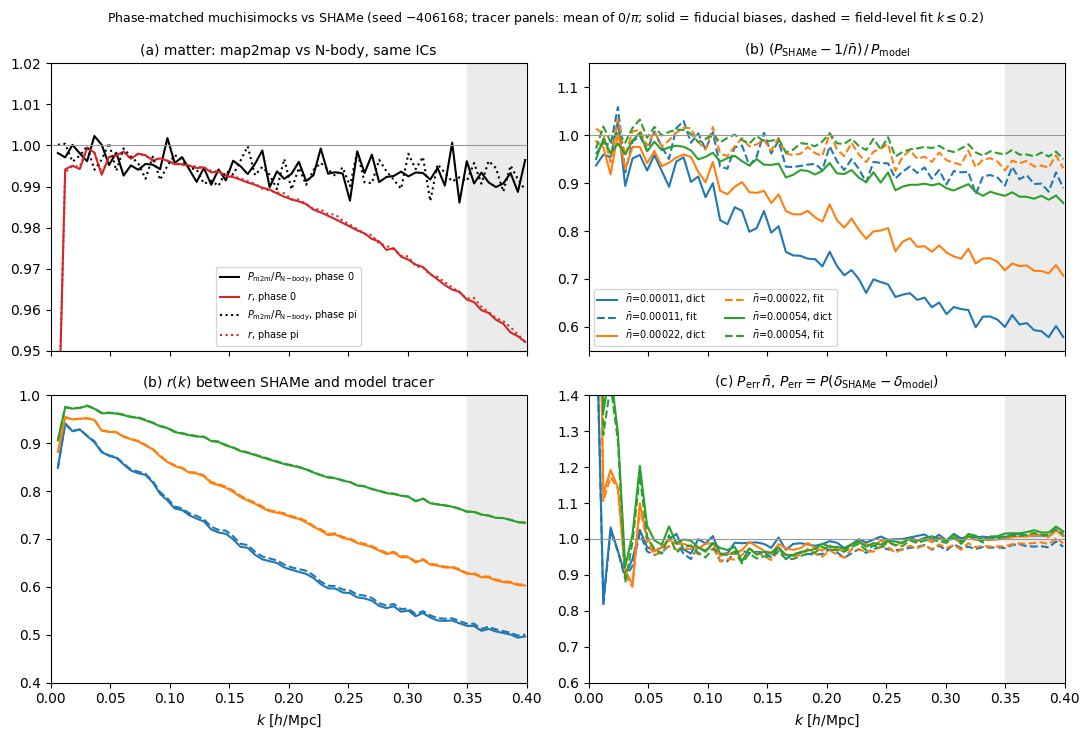

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
ax_m, ax_p, ax_r, ax_e = axes.ravel()
colors_sh = dict(zip(tags_shame, ['C0', 'C1', 'C2']))
ls_lab = {'dict': '-', 'fit': '--'}

for ph, ls in zip(phases_sh, ['-', ':']):
    ax_m.plot(k_sh, res_sh[('matter', ph)]['ratio'], 'k', ls=ls, label=rf'$P_\mathrm{{m2m}}/P_\mathrm{{N\!-\!body}}$, phase {ph}')
    ax_m.plot(k_sh, res_sh[('matter', ph)]['r'], 'C3', ls=ls, label=rf'$r$, phase {ph}')
ax_m.axhline(1, color='0.6', lw=0.8)
ax_m.set_ylim(0.95, 1.02)
ax_m.set_title('(a) matter: map2map vs N-body, same ICs', fontsize=10)
ax_m.legend(fontsize=7)

for tag in tags_shame:
    c = colors_sh[tag]
    for lab in ['dict', 'fit']:
        kw = dict(color=c, ls=ls_lab[lab])
        ax_p.plot(k_sh, pmean(tag, lab, 'ratio_sn'), label=rf'$\bar n$={tag[5:]}, {lab}' , **kw)
        ax_r.plot(k_sh, pmean(tag, lab, 'r'), **kw)
        ax_e.plot(k_sh, pmean(tag, lab, 'perr_nbar'), **kw)
ax_p.axhline(1, color='0.6', lw=0.8)
ax_p.set_ylim(0.55, 1.15)
ax_p.set_title(r'(b) $(P_\mathrm{SHAMe} - 1/\bar n)\,/\,P_\mathrm{model}$', fontsize=10)
ax_p.legend(fontsize=7, ncol=2)
ax_r.set_title(r'(b) $r(k)$ between SHAMe and model tracer', fontsize=10)
ax_r.set_ylim(0.4, 1.0)
ax_e.axhline(1, color='0.6', lw=0.8)
ax_e.set_title(r'(c) $P_\mathrm{err}\,\bar n$, $P_\mathrm{err}=P(\delta_\mathrm{SHAMe}-\delta_\mathrm{model})$', fontsize=10)
ax_e.set_ylim(0.6, 1.4)
for ax in axes.ravel():
    ax.axvspan(kmax_analysis, k_sh.max(), color='0.92', zorder=0)
    ax.set_xlim(0, 0.4)
for ax in axes[1]:
    ax.set_xlabel(r'$k$ [$h$/Mpc]')
fig.suptitle(r'Phase-matched muchisimocks vs SHAMe (seed $-406168$; tracer panels: mean of $0/\pi$; solid = fiducial biases, dashed = field-level fit $k\leq0.2$)', fontsize=9)
fig.tight_layout()
plt.show()

**Conclusions** (numbers are means over the $0/\pi$ pair, $k = 0.05 \to 0.35\,h$/Mpc):

- **(a) Matter.** With identical ICs, map2map reproduces the N-body matter $P(k)$ to $\lesssim1\%$ ($0.991$–$0.998$) over the whole range, and the fields agree mode by mode: $r = 0.997$ at $k=0.05$, $0.987$ at $0.2$, $0.963$ at $0.35$. The two phases agree, so this is not a fluke of one realization. The small decorrelation at high $k$ is map2map's own error (plus the $3072^3$ vs. $524^3$ particle resolution), and it is far below the tracer stochasticity below.
- **(b) Deterministic tracer.** With the **fiducial** `bias_dict_shame` biases, the model has *too much* small-scale power: $(P_\mathrm{SHAMe}-1/\bar n)/P_\mathrm{model}$ drops from $0.93$–$0.97$ at $k=0.05$ to $0.60$ / $0.72$ / $0.87$ at $k=0.35$ for $\bar n = 1.1, 2.2, 5.4\times10^{-4}$. **Biases fit at field level** to the same catalogs ($k\le0.2$) bring it to within $\sim3\%$ up to $k=0.2$ and $4$–$10\%$ at $0.35$. The fits agree with the fiducial $b_1$ to $3\%$ but prefer much smaller $|b_2|, |b_{s^2}|$ and especially $|b_{\nabla^2}| \approx 0.25$ (fiducial $\approx 0.8$). Removing the factor of 2 on $b_2, b_{s^2}$ in `bias_dict_shame` only partly closes the gap ($\bar n=2.2\times10^{-4}$: $0.79$ instead of $0.72$ at $k=0.35$), so the main mismatch is in $b_{\nabla^2}$. This doesn't affect the inference, where the biases are free parameters, but the fiducial values shouldn't be described as "the SHAMe biases" for our operator basis. $r(k)$ between SHAMe and model is almost the same for both bias sets ($0.63$–$0.76$ at $k=0.35$), because it is set by shot noise, not by the bias values.
- **(c) Stochasticity.** The residual $P_\mathrm{err} = P(\delta_\mathrm{SHAMe} - \delta_\mathrm{model})$ is **Poisson to a few percent**: $P_\mathrm{err}\bar n = 0.95$–$1.01$ for $k\gtrsim0.05$, for all three densities and both bias sets (slightly sub-Poisson, $\approx0.97$, around $k\sim0.1$–$0.2$; the $k<0.05$ excursions are few-mode noise). So, once sample variance is removed, SHAMe's stochastic part is close to white shot noise with amplitude $1/\bar n$. That is a useful anchor for the noise-model amplitudes.

### 2.1 Grids and box size

Everything in this comparison uses **box $L = 1024\,h^{-1}$Mpc**, the SHAMe/Rings box. It has to: the phases are only identical mode by mode if the Fourier grid ($k_f = 2\pi/1024$) is the same as the simulation's.

| | deposit grid | cell [$h^{-1}$Mpc] | target grid (k-cut) | cell [$h^{-1}$Mpc] | $k_N$ of target [$h$/Mpc] |
|---|---|---|---|---|---|
| muchisimocks library ($L=1000$) | $512^3$ | 1.953 | $128^3$ | 7.813 | 0.402 |
| matched muchisimocks ($L=1024$) | $524^3$ | 1.954 | $132^3$ | 7.758 | 0.405 |
| SHAMe tracer & matter ($L=1024$) | $524^3$ | 1.954 | $132^3$ | 7.758 | 0.405 |

- **matched vs. SHAMe:** identical grids, identical pipeline (CIC deposit on $524^3$ → $k$-cut to $132^3$ → CIC deconvolution, `process_mock_catalogs.py`), so the fields can be compared cell by cell.
- **matched vs. library:** the deposit cell (map2map's operating scale) matches to $0.07\%$. The target cell is $0.7\%$ smaller because $1024/7.8125 = 131.07$ is rounded to the nearest even integer (`round_to_nearest_even`). That only moves the $k$-cut/Nyquist from $0.402$ to $0.405\,h$/Mpc, above our $k_\mathrm{max}=0.35$. All statistics are binned in physical $k$ with the same edges ($0.01$–$0.4$), so the data vectors line up.
- Particle resolution is the one thing that does not match: map2map moves $524^3$ particles, the Rings run has $3072^3$.

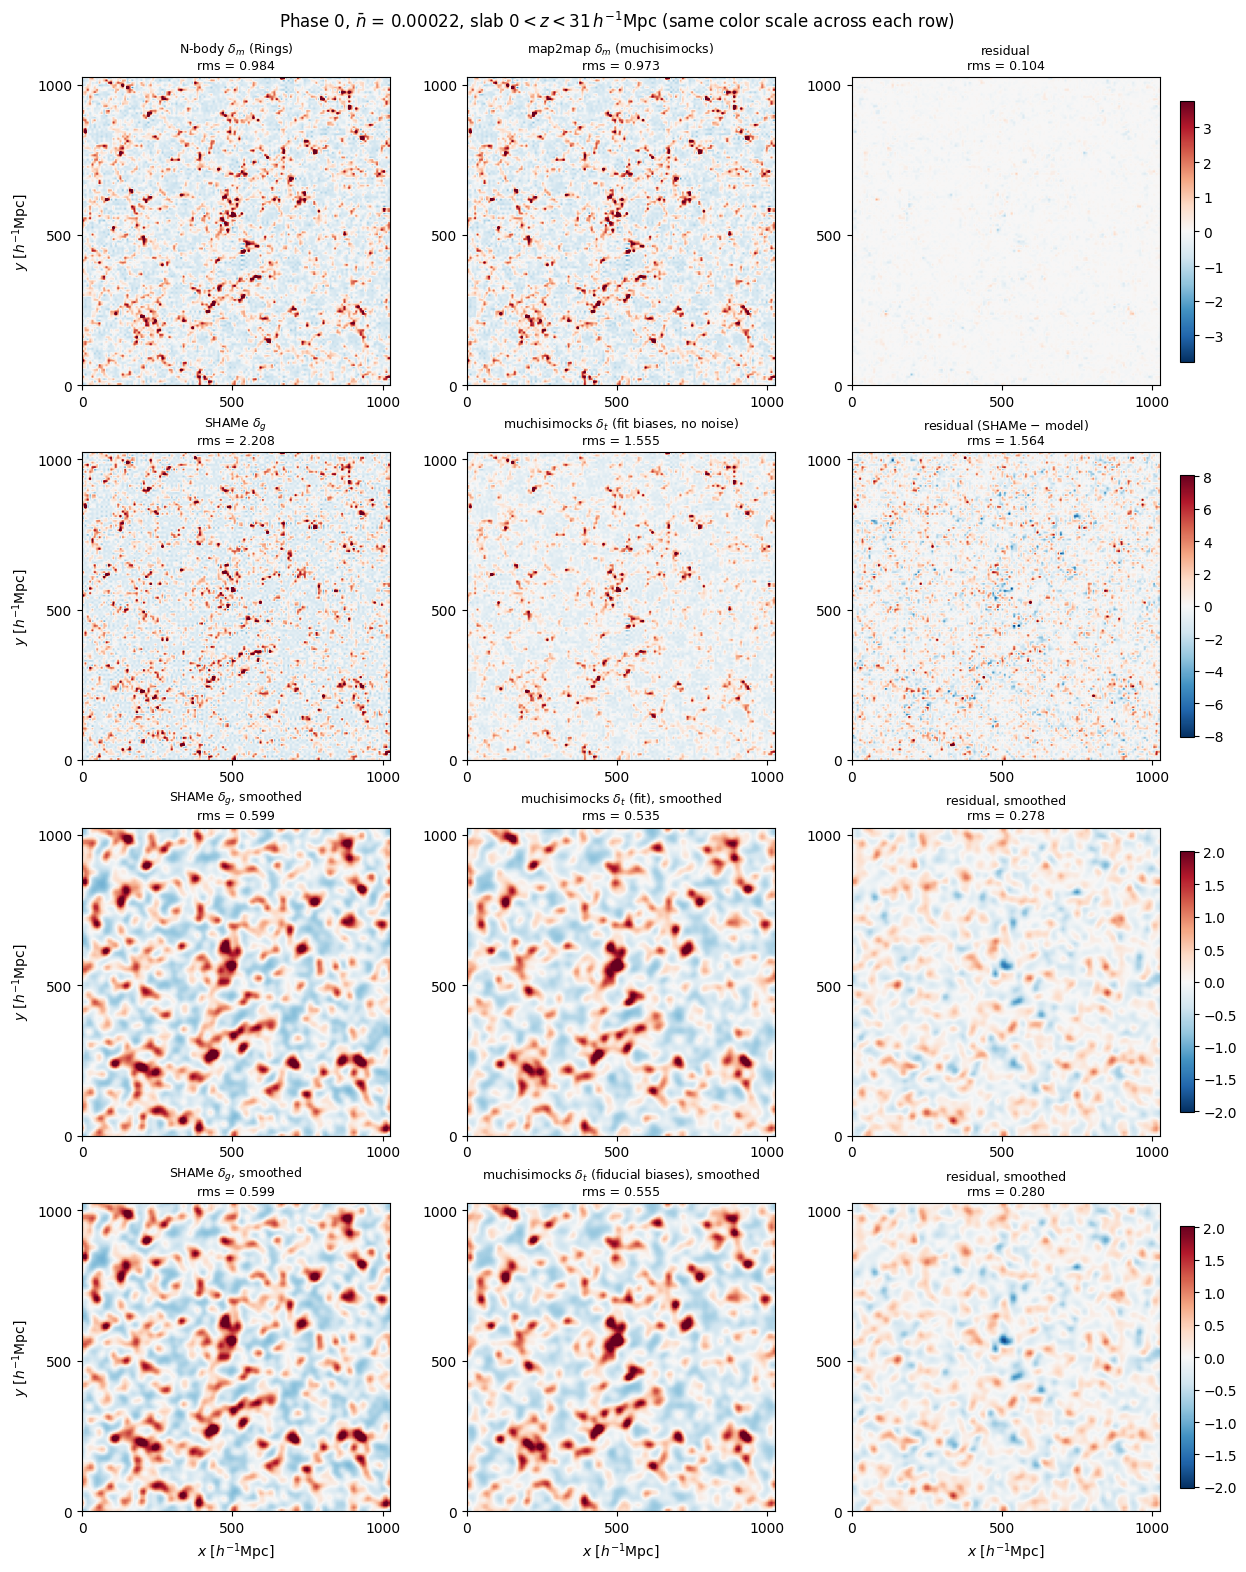

In [8]:
from scipy.ndimage import gaussian_filter

phase_show, tag_show = '0', '_nbar0.00022'
nslab = 4                                  # slab thickness in cells (4 x 7.76 = 31 Mpc/h)
R_smooth = 10.0                            # h^-1 Mpc, for the smoothed tracer row
cell = L_SH / NG_SH

ops_show = load_matched_ops(phase_show)
t_shame, dm_nbody = load_shame_fields(phase_show, tag_show)
b_fit_show = res_sh[(tag_show, phase_show)]['fit']['b']
b_dict_show = res_sh[(tag_show, phase_show)]['dict']['b']
dm_m2m = ops_show[0] - 1
t_model = dm_m2m + sum(b * o for b, o in zip(b_fit_show, ops_show[1:]))
t_model_dict = dm_m2m + sum(b * o for b, o in zip(b_dict_show, ops_show[1:]))

def slab(f):
    return f[:, :, :nslab].mean(axis=-1)

sm = lambda f: gaussian_filter(f, R_smooth / cell, mode='wrap')
rows = [
    ('matter', [r'N-body $\delta_m$ (Rings)', r'map2map $\delta_m$ (muchisimocks)', 'residual'],
     [dm_nbody, dm_m2m, dm_m2m - dm_nbody]),
    ('tracer', [r'SHAMe $\delta_g$', r'muchisimocks $\delta_t$ (fit biases, no noise)', 'residual (SHAMe $-$ model)'],
     [t_shame, t_model, t_shame - t_model]),
    (f'tracer, $R={R_smooth:.0f}$', [rf'SHAMe $\delta_g$, smoothed', rf'muchisimocks $\delta_t$ (fit), smoothed', 'residual, smoothed'],
     [sm(t_shame), sm(t_model), sm(t_shame - t_model)]),
    (f'tracer, $R={R_smooth:.0f}$, dict', [rf'SHAMe $\delta_g$, smoothed', rf'muchisimocks $\delta_t$ (fiducial biases), smoothed', 'residual, smoothed'],
     [sm(t_shame), sm(t_model_dict), sm(t_shame - t_model_dict)]),
]
fig, axes = plt.subplots(len(rows), 3, figsize=(12.5, 3.9 * len(rows)), layout='constrained')
ext = [0, L_SH, 0, L_SH]
for (rowname, titles, fs), axrow in zip(rows, axes):
    vmax = np.percentile(np.abs(slab(fs[0])), 99)
    for f, ttl, ax in zip(fs, titles, axrow):
        im = ax.imshow(slab(f).T, origin='lower', extent=ext, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
        ax.set_title(ttl + f'\nrms = {slab(f).std():.3f}', fontsize=9)
        ax.set_xticks([0, 500, 1000]); ax.set_yticks([0, 500, 1000])
    fig.colorbar(im, ax=axrow, shrink=0.85, pad=0.01)
    axrow[0].set_ylabel(r'$y$ [$h^{-1}$Mpc]')
for ax in axes[-1]:
    ax.set_xlabel(r'$x$ [$h^{-1}$Mpc]')
fig.suptitle(rf'Phase {phase_show}, $\bar n$ = {tag_show[5:]}, slab $0<z<{nslab * cell:.0f}\,h^{{-1}}$Mpc (same color scale across each row)')
plt.show()

### 2.2 Summary statistics: $P(k)$, $P_{gm}(k)$, $B(k_1,k_2,k_3)$

All computed with the production estimators and binning (`compute_statistics.compute_pk` / `compute_pgm`, PolyBin3D `Bk_ideal` monopole; box 1024, $132^3$) by `code/compute_shame_matched_stats.py` (Slurm: `job_shame_matched_stats.s`). The SHAMe curves are the stored data vectors (`data/data_shame/data{nbar}_phase{0,pi}/`). Everything is averaged over the $0/\pi$ pair; $B$ is in physical units ($\times\,132^9$, as `data_loader.load_bispec` does).

**What is compared.** The muchisimocks tracer is deterministic (field-level-fit biases, and fiducial `bias_dict_shame`), plus the shot noise it **would** have if Poisson-sampled at the SHAMe density:
$$P^\mathrm{model} + \frac{1}{\bar n}, \qquad B^\mathrm{model} + \frac{P^\mathrm{model}_1+P^\mathrm{model}_2+P^\mathrm{model}_3}{\bar n} + \frac{1}{\bar n^2},$$
against the **raw** SHAMe statistics. $P_i$ are evaluated at the triangle's bin centers. Dotted curves are the deterministic model without the shot-noise terms. $P_{gm}$ has no shot noise.
I checked the units and the shot-noise normalization with a Poisson random catalog run through the same deposit → $k$-cut → deconvolve → estimator chain: $P\bar n = 1.00$, and `Bk_ideal` $= \bar n^{-2}/132^9$ (median over triangles).

*Why not subtract shot noise from SHAMe instead:* with Poisson subtraction, SHAMe's $B$ goes **negative** for high-$k$ triangles. SHAMe's 3-point stochasticity is strongly **sub-Poisson**, even though its 2-point residual is Poisson to $\sim3\%$ (§2c), so the ratio would be meaningless there.

$P_{gm}$ is always taken against the **N-body** matter mesh, the same field the SHAMe $P_{gm}$ uses. The dash-dot curve is what the **production pipeline** computes for muchisimocks, with the $\delta$ operator (`bias_terms_eul[1]`, `compute_statistics.py:329`) as "matter".

(The stats file also has variants with a toy multiplicative noise $(1+\delta_m)A\epsilon$ at the Poisson level. They aren't the paper's noise model, so they're left out here.)

Residuals are model / SHAMe $- 1$. The grey band is the per-bin Gaussian error of SHAMe $P$ for one box, for scale only. With matched phases the scatter is much smaller, except at the lowest $k$, where SHAMe's own shot-noise realization is not matched.

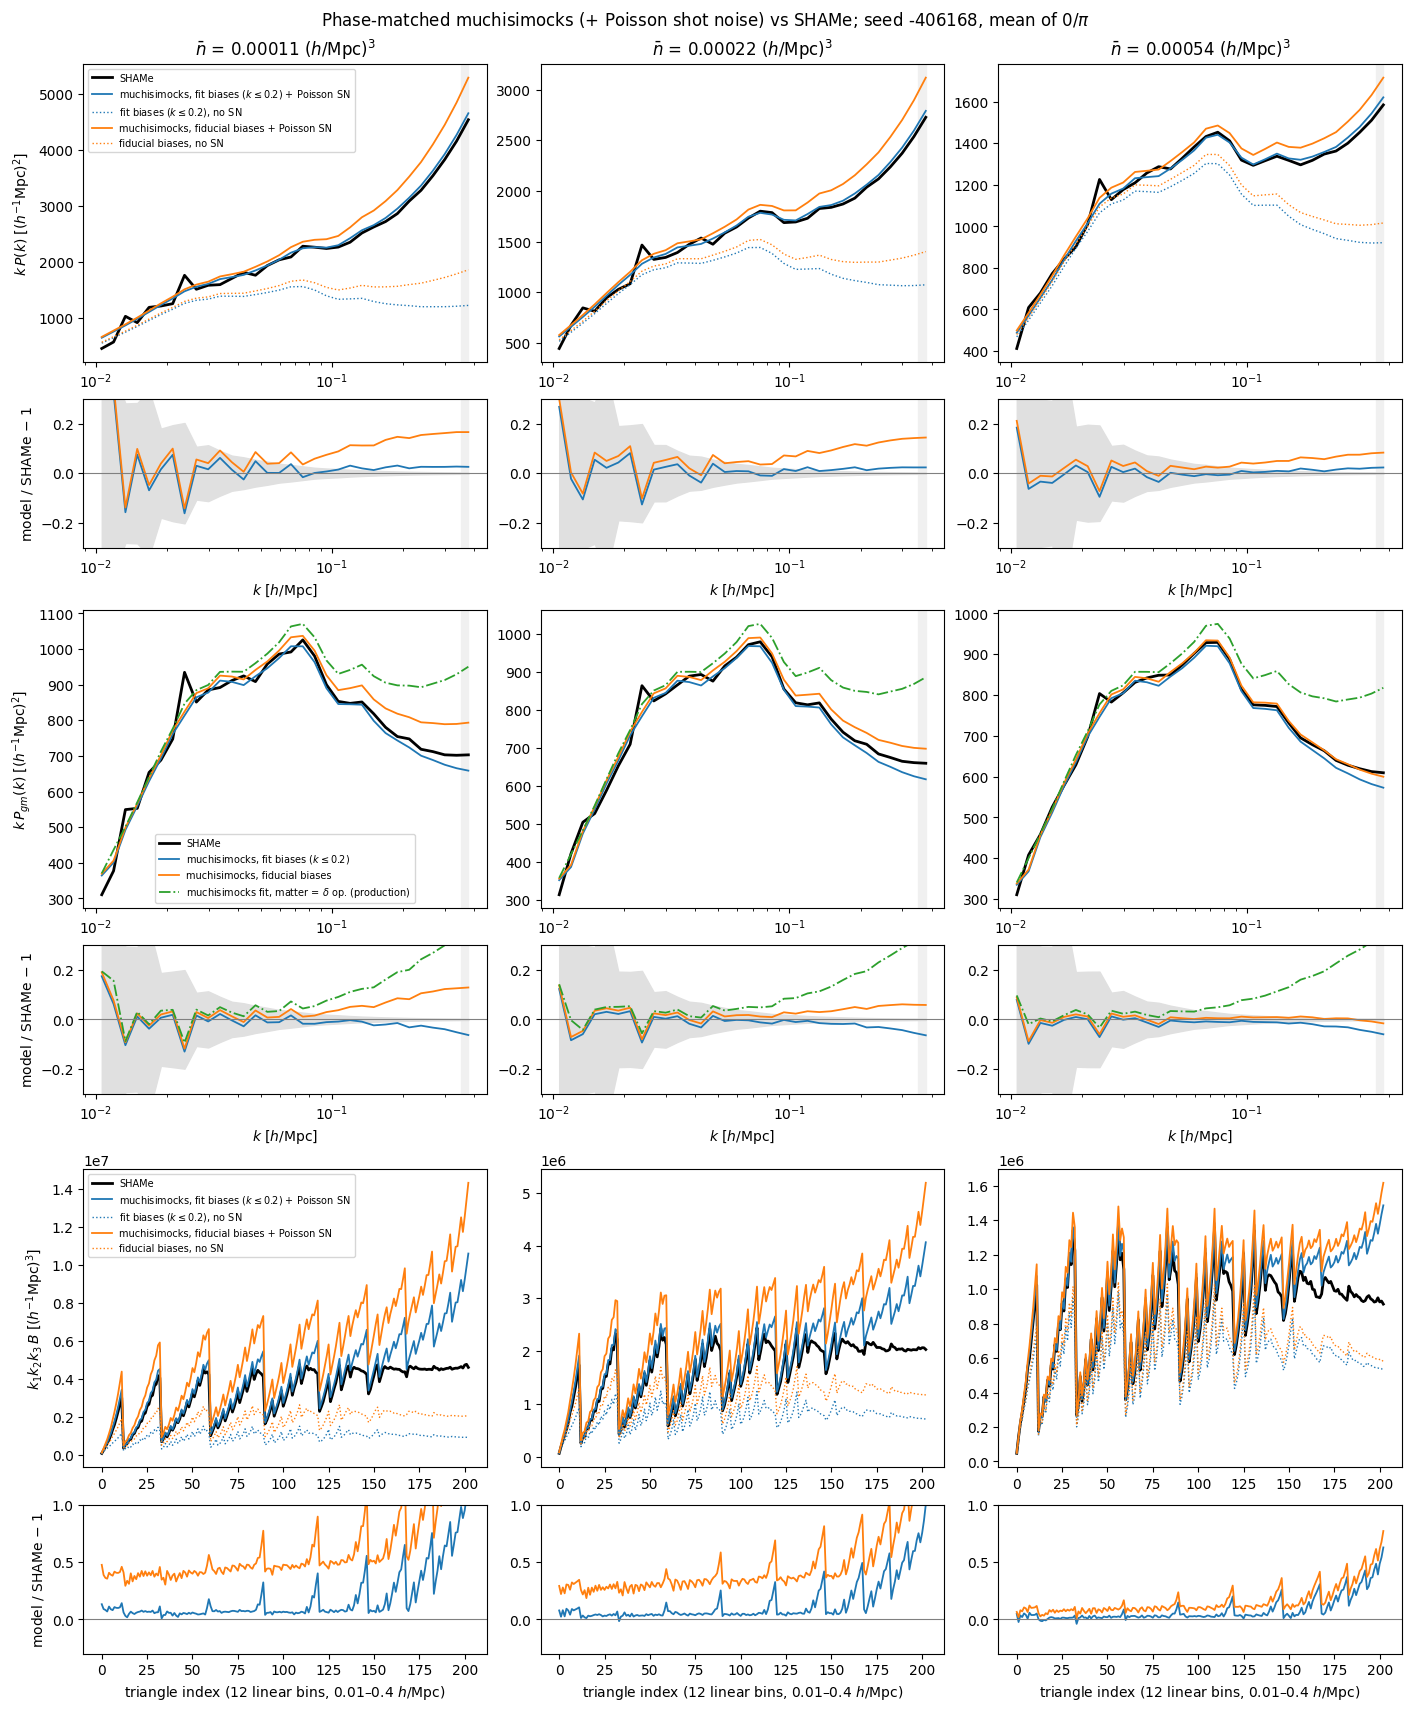

|model / SHAMe - 1|, median / max   (P, Pgm: 0.03 <= k <= 0.35;  B: all 203 triangles)
                                              _nbar0.00011                        _nbar0.00022                        _nbar0.00054
                                 P         Pgm           B           P         Pgm           B           P         Pgm           B
fit biases ($k         0.024/0.062 0.017/0.052 0.074/1.300 0.016/0.038 0.017/0.054 0.052/1.001 0.009/0.035 0.012/0.050 0.034/0.627
fiducial biase         0.091/0.165 0.042/0.125 0.475/2.108 0.073/0.141 0.029/0.061 0.348/1.556 0.043/0.080 0.006/0.019 0.108/0.771
fit, Pgm vs delta op             - 0.090/0.324           -           - 0.086/0.314           -           - 0.084/0.312           -


In [12]:
stats_m = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'stats.npy', allow_pickle=True).item()
B_NORM = float(NG_SH)**9            # PolyBin Bk_ideal on delta/N^3 fields -> physical (load_bispec convention)
k123_st = stats_m['k123']
wB = stats_m['weight']
itri = np.arange(len(wB))
k_st = stats_m[(tags_shame[0], '0')]['k']

def shame_raw(tag, stat):
    vals = []
    for ph in phases_sh:
        d = np.load(msm.DIR_DATA_SHAME / f'data{tag}_phase{ph}' / f'{stat}s' / f'{stat}.npy', allow_pickle=True).item()
        vals.append(d['bispectrum']['b0'] * B_NORM if stat == 'bispec' else d['pk'])
        err = None if stat == 'bispec' else d['pk_gaussian_error']
    return np.mean(vals, axis=0), err

def model_det(tag, var, stat, matter='nbody'):
    vals = []
    for ph in phases_sh:
        r = stats_m[(tag, ph)][var]
        vals.append({'pk': r['pk'], 'pgm': r['pgm'][matter], 'bispec': r['bk'] * B_NORM}[stat])
    return np.mean(vals, axis=0)

def model_obs(tag, var, stat, matter='nbody'):
    # deterministic model + the shot noise it would have if Poisson-sampled at nbar
    nbar = float(tag.split('nbar')[1])
    det = model_det(tag, var, stat, matter)
    if stat == 'pk':
        return det + 1 / nbar
    if stat == 'pgm':
        return det
    p_i = np.exp(np.interp(np.log(k123_st), np.log(k_st), np.log(model_det(tag, var, 'pk'))))   # (3, ntri)
    return det + p_i.sum(axis=0) / nbar + 1 / nbar**2

variants = [('fit', 'C0', rf'muchisimocks, fit biases ($k\leq{kmax_fit}$)'),
            ('dict', 'C1', 'muchisimocks, fiducial biases')]
stat_labels = {'pk': r'$k\,P(k)$ [$(h^{-1}$Mpc$)^2$]', 'pgm': r'$k\,P_{gm}(k)$ [$(h^{-1}$Mpc$)^2$]',
               'bispec': r'$k_1k_2k_3\,B$ [$(h^{-1}$Mpc$)^3$]'}

fig, axes = plt.subplots(6, 3, figsize=(14, 17), sharex='row',
                         gridspec_kw=dict(height_ratios=[2, 1, 2, 1, 2, 1]), layout='constrained')
for j, tag in enumerate(tags_shame):
    for irow, stat in enumerate(['pk', 'pgm', 'bispec']):
        ax, axr = axes[2 * irow, j], axes[2 * irow + 1, j]
        sh, err = shame_raw(tag, stat)
        x = itri if stat == 'bispec' else k_st
        scale = wB if stat == 'bispec' else k_st
        ax.plot(x, scale * sh, 'k', lw=2, label='SHAMe')
        for var, c, lab in variants:
            m = model_obs(tag, var, stat)
            ax.plot(x, scale * m, color=c, lw=1.3, label=lab + ('' if stat == 'pgm' else ' + Poisson SN'))
            if stat != 'pgm':
                ax.plot(x, scale * model_det(tag, var, stat), color=c, ls=':', lw=1, label=lab.replace('muchisimocks, ', '') + ', no SN')
            axr.plot(x, m / sh - 1, color=c, lw=1.3)
        if stat == 'pgm':
            m = model_obs(tag, 'fit', stat, matter='O1')
            ax.plot(x, scale * m, color='C2', ls='-.', lw=1.3, label=r'muchisimocks fit, matter = $\delta$ op. (production)')
            axr.plot(x, m / sh - 1, color='C2', ls='-.', lw=1.3)
        if err is not None:
            axr.fill_between(x, -err / sh, err / sh, color='0.88', zorder=0)
            for a in (ax, axr):
                a.axvspan(kmax_analysis, x.max(), color='0.94', zorder=-1)
                a.set_xscale('log')
        axr.axhline(0, color='0.5', lw=0.8)
        axr.set_ylim(*((-0.3, 1.0) if stat == 'bispec' else (-0.3, 0.3)))
        if j == 0:
            ax.set_ylabel(stat_labels[stat]); axr.set_ylabel('model / SHAMe $-$ 1')
            ax.legend(fontsize=7)
        if irow == 0:
            ax.set_title(rf'$\bar n$ = {tag[5:]} $(h/\mathrm{{Mpc}})^3$')
        axr.set_xlabel('triangle index (12 linear bins, 0.01–0.4 $h$/Mpc)' if stat == 'bispec' else r'$k$ [$h$/Mpc]')
fig.suptitle(f'Phase-matched muchisimocks (+ Poisson shot noise) vs SHAMe; seed {SEED_SH}, mean of $0/\\pi$')
plt.show()

# Summary: median and max |residual|; P, Pgm over 0.03 <= k <= kmax_analysis (lowest bins are SHAMe shot-noise-dominated scatter)
mk = (k_st >= 0.03) & (k_st <= kmax_analysis)
print(f'|model / SHAMe - 1|, median / max   (P, Pgm: {0.03} <= k <= {kmax_analysis};  B: all {len(wB)} triangles)')
print(f"{'':22s}" + ''.join(f'{t:>36s}' for t in tags_shame))
print(f"{'':22s}" + ''.join(f"{'P':>12s}{'Pgm':>12s}{'B':>12s}" for _ in tags_shame))
rows = [(v, lab.split(',')[1].strip()[:14], 'nbody') for v, _, lab in variants] + [('fit', 'fit, Pgm vs delta op', 'O1')]
for var, lab, matter in rows:
    line = ''
    for tag in tags_shame:
        for stat in ['pk', 'pgm', 'bispec']:
            if matter == 'O1' and stat != 'pgm':
                line += f"{'-':>12s}"; continue
            r = np.abs(model_obs(tag, var, stat, matter) / shame_raw(tag, stat)[0] - 1)
            r = r if stat == 'bispec' else r[mk]
            line += f'{np.median(r):6.3f}/{r.max():5.3f}'
    print(f'{lab:22s}{line}')

**Conclusions, §2.2** (fit biases unless stated; $P$, $P_{gm}$ over $0.03\le k\le0.35$; median / max of $|\mathrm{model}/\mathrm{SHAMe}-1|$):

| $\bar n$ | $P$ | $P_{gm}$ | $B$ (all 203 triangles) | $P_{gm}$, production ($\delta$ op. as matter) |
|---|---|---|---|---|
| $1.1\times10^{-4}$ | 2.4% / 6% | 1.7% / 5% | 7% / 130% | 9% / 32% |
| $2.2\times10^{-4}$ | 1.6% / 4% | 1.7% / 5% | 5% / 100% | 9% / 31% |
| $5.4\times10^{-4}$ | 0.9% / 3.5% | 1.2% / 5% | 3% / 63% | 8% / 31% |

- **$P$ and $P_{gm}$:** with matched phases, the muchisimocks bias model (+ Poisson shot noise) reproduces SHAMe to a few percent over the whole analysis range. The largest deviations are $P_{gm}$ running $\sim5\%$ low at $k\to0.35$, and the lowest-$k$ bins, where SHAMe's unmatched shot-noise realization scatters a few-mode bin by $\sim10$–$20\%$. The fiducial biases are 2–4× worse (P up to $8$–$17\%$ high at $k=0.35$), consistent with §2(b).
- **$B$:** the deterministic model is right at low $k$ ($\lesssim5\%$ for most triangles), but **Poisson** shot noise overshoots SHAMe for triangles with large $k_i$, by up to a factor ~2 at $k_i \sim 0.4$. SHAMe's 3-point stochasticity is strongly sub-Poisson there (Poisson-subtracted SHAMe $B$ goes negative), even though its 2-point stochasticity is Poisson to 3%. So the noise model's freedom matters most for $B$: a noise model fit only to the $P$ level would get $B$ wrong. This argues for the second-order/multiplicative noise terms ($A^{(2)}$), which can produce a non-Poisson 3-point stochastic contribution.
- **⚠ $P_{gm}$ pipeline inconsistency:** for muchisimocks, `compute_statistics.py:329` uses `bias_terms_eul[1]` (the advected $\delta$ operator) as the matter field, but the SHAMe data vector uses the true N-body matter. On identical ICs, these differ by $8$–$9\%$ (median) and **~31% at $k=0.35$**, with the same sign at all three densities. Compared like for like (N-body or map2map $O_1$ matter), the agreement is ~2%. The muchisimocks $P_{gm}$ should use `bias_terms_eul[0]` (map2map nonlinear matter), or the SHAMe $P_{gm}$ should be recomputed against the matched $\delta$ operator, before the SHAMe $P_{gm}$ results are interpreted.

### 2.3 Populated like the cosmic-variance set: SHAMe biases + best-fit noise

This is the paper's configuration for the fixed-SHAMe-cosmology test set (`_shame_p0_n1000`, scenario `noisy` in `generate_config_inference._TEST_SCENARIO_TAGS`), applied to the matched mock: `tag_biasparams = _biasshame_noisebest_p0_n1`, i.e. the measured SHAMe biases for $\bar n = 2.2\times10^{-4}$ (same values as `bias_dict_shame['_nbar0.00022']`, the "fiducial" curves above) plus the best-fit multiplicative noise amplitudes $(A_\mathrm{homog}, A_{b_1}, A_{b_2}, A_{b_{s^2}}, A_{b_\nabla})$ on unit Gaussian noise fields, built with `utils_model.get_tracer_field(..., noise_model='multiplicative')` exactly as `compute_statistics.make_tracer_field` does. Script: `code/compute_shame_matched_noisebest.py` (Slurm `job_shame_matched_noisebest.s`).

Because of the matched grid, two things differ from the library: the unit noise fields are drawn fresh at $132^3$ (10 realizations, the same seed for both phases of a pair), and **all five** noise amplitudes $A$ are multiplied by $(V_\mathrm{cell,lib}/V_\mathrm{cell,matched})^{1/2} = 1.011$. Why: a unit-variance white field $\epsilon$ on a grid has $P_\epsilon(k) = V_\mathrm{cell}$, so the noise term $A\,\epsilon\,O_i$ has power $\propto A^2 V_\mathrm{cell}$. The matched cells ($1024/132 = 7.758\,h^{-1}$Mpc) are $2.1\%$ smaller in volume than the library's ($1000/128 = 7.8125$), so the same $A$ would give $2.1\%$ less physical noise power; scaling $A$ by $\sqrt{1.021}$ restores it. The purple curve uses the library $A$ unchanged (`compute_shame_matched_noisebest.py --no-rescale`) to show how much this matters.

The noise is not phase-matched to SHAMe's own stochasticity, so the band shows the 16–84% spread over the 10 noise realizations (each one a $0/\pi$ pair mean). The deterministic part is still free of cosmic variance. **Curves:**
- **black, thick:** SHAMe $\bar n = 2.2\times10^{-4}$, raw statistics (shot noise included), mean of the $0/\pi$ pair.
- **red solid + band:** matched muchisimocks, SHAMe biases + best-fit multiplicative noise with rescaled $A$ (the CV-set configuration). Line = median of the 10 noise realizations, band = 16–84%.
- **purple solid + band** ($P$, $B$ only): the same, but with $A$ **not** rescaled. Not shown for $P_{gm}$ because the noise is uncorrelated with matter, so it can't change $P_{gm}$.
- **blue dashed** ($P_{gm}$ only): the same tracer field as red solid, cross-correlated with map2map's own nonlinear matter, $\mathcal{O}_1$ (bias field 0, the '1' operator), instead of the N-body mesh. This is the matter field the library mocks *should* use, since they have no N-body run.
- **red dash-dot** ($P_{gm}$ only): the same tracer field as red solid, but the "matter" it is cross-correlated with is the $\delta$ operator, not the N-body matter mesh. This is what the production pipeline computes for every muchisimocks mock (`compute_statistics.py:329` uses `bias_terms_eul[1]`). The $\delta$ operator is the *linear* field $\delta_L$ carried to the map2map positions, so it is missing the nonlinear growth of the true matter field. SHAMe's stored $P_{gm}$ uses the N-body matter. The gap between red solid and red dash-dot is therefore the size of that pipeline inconsistency (§2.2 warning), not a bias/noise model error.
- **orange dashed:** SHAMe biases, no noise field, plus analytic Poisson shot noise for $P$ and $B$ (none for $P_{gm}$), as in §2.2.

_biasshame_noisebest_p0_n1: b = [ 0.4741  0.127  -0.3388 -0.8244]
A_noise (x1.0106) = [ 2.3714 -1.3577 -0.2285  0.5322  1.6993],  n_real = 10
no-rescale check: A_noise (x1.0000) = [ 2.3465 -1.3434 -0.2261  0.5266  1.6814]


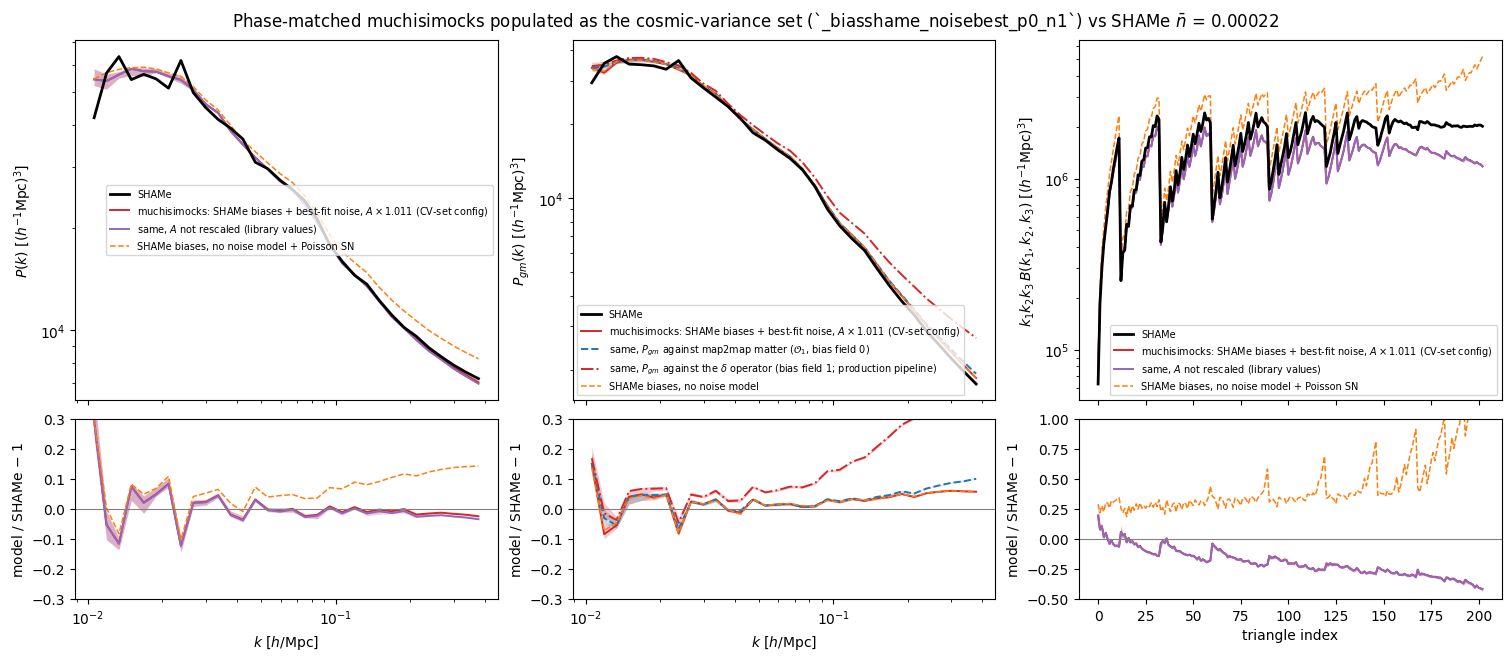

|model / SHAMe - 1| (median over noise realizations of: median / max over bins; P, Pgm: 0.03 <= k <= 0.35; B: all triangles)
  P              0.012 / 0.048
  Pgm            0.031 / 0.061
  Pgm, m2m O_1   0.032 / 0.093
  Pgm, delta op  0.131 / 0.493
  B              0.210 / 0.418
P ratio at k = [0.1, 0.2, 0.3, 0.35] : [1.009 1.    0.984 0.981]


In [13]:
nb_stats = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'stats_noisebest.npy', allow_pickle=True).item()
tag_nb = nb_stats['tag_mock']
print(f"{nb_stats['tag_biasparams']}: b = {np.round(nb_stats['b'], 4)}")
print(f"A_noise (x{nb_stats['V_scale']:.4f}) = {np.round(nb_stats['A_noise'], 4)},  n_real = {nb_stats['n_real']}")

fn_norescale = msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'stats_noisebest_norescale.npy'
nb_stats_norescale = np.load(fn_norescale, allow_pickle=True).item() if fn_norescale.exists() else None
if nb_stats_norescale is not None:
    print(f"no-rescale check: A_noise (x{nb_stats_norescale['V_scale']:.4f}) = {np.round(nb_stats_norescale['A_noise'], 4)}")

def nb_real(stat, matter='nbody', st=None):
    # (n_real, nbins): pair mean for each noise realization
    st = nb_stats if st is None else st
    get = {'pk': lambda d: d['pk'], 'pgm': lambda d: d['pgm'][matter], 'bispec': lambda d: d['bk'] * B_NORM}[stat]
    return 0.5 * (get(st['0']) + get(st['pi']))

stat_labels_raw = {'pk': r'$P(k)$ [$(h^{-1}$Mpc$)^3$]', 'pgm': r'$P_{gm}(k)$ [$(h^{-1}$Mpc$)^3$]',
                   'bispec': r'$k_1k_2k_3\,B(k_1,k_2,k_3)$ [$(h^{-1}$Mpc$)^3$]'}

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex='col',
                         gridspec_kw=dict(height_ratios=[2, 1]), layout='constrained')
for j, stat in enumerate(['pk', 'pgm', 'bispec']):
    ax, axr = axes[0, j], axes[1, j]
    sh, err = shame_raw(tag_nb, stat)
    x = itri if stat == 'bispec' else k_st
    scale = wB if stat == 'bispec' else 1.0     # B always shown as k1 k2 k3 B (the data vector)
    ax.plot(x, scale * sh, 'k', lw=2, label='SHAMe', zorder=5)
    curves = [(nb_real(stat), 'C3', '-', r'muchisimocks: SHAMe biases + best-fit noise, $A\times1.011$ (CV-set config)')]
    if nb_stats_norescale is not None and stat != 'pgm':   # noise doesn't enter P_gm
        curves.append((nb_real(stat, st=nb_stats_norescale), 'C4', '-', r'same, $A$ not rescaled (library values)'))
    if stat == 'pgm':
        curves.append((nb_real(stat, 'm2m'), 'C0', '--', r'same, $P_{gm}$ against map2map matter ($\mathcal{O}_1$, bias field 0)'))
        curves.append((nb_real(stat, 'delta_op'), 'C3', '-.', r'same, $P_{gm}$ against the $\delta$ operator (bias field 1; production pipeline)'))
    for arr, c, ls, lab in curves:
        lo, med, hi = np.percentile(arr, [16, 50, 84], axis=0)
        ax.plot(x, scale * med, color=c, ls=ls, lw=1.4, label=lab)
        ax.fill_between(x, scale * lo, scale * hi, color=c, alpha=0.25, lw=0)
        axr.plot(x, med / sh - 1, color=c, ls=ls, lw=1.4)
        axr.fill_between(x, lo / sh - 1, hi / sh - 1, color=c, alpha=0.25, lw=0)
    m_ref = model_obs(tag_nb, 'dict', stat)
    ax.plot(x, scale * m_ref, color='C1', ls='--', lw=1.1, label='SHAMe biases, no noise model' + ('' if stat == 'pgm' else ' + Poisson SN'))
    axr.plot(x, m_ref / sh - 1, color='C1', ls='--', lw=1.1)
    if stat != 'bispec':
        for a in (ax, axr):
            a.set_xscale('log')
    axr.axhline(0, color='0.5', lw=0.8)
    axr.set_ylim(*((-0.5, 1.0) if stat == 'bispec' else (-0.3, 0.3)))
    ax.set_yscale('log')
    ax.set_ylabel(stat_labels_raw[stat]); axr.set_ylabel('model / SHAMe $-$ 1')
    axr.set_xlabel('triangle index' if stat == 'bispec' else r'$k$ [$h$/Mpc]')
    ax.legend(fontsize=7)
fig.suptitle(rf'Phase-matched muchisimocks populated as the cosmic-variance set (`{nb_stats["tag_biasparams"]}`) vs SHAMe $\bar n$ = {tag_nb[5:]}')
plt.show()

mk = (k_st >= 0.03) & (k_st <= kmax_analysis)
print(f'|model / SHAMe - 1| (median over noise realizations of: median / max over bins; P, Pgm: 0.03 <= k <= {kmax_analysis}; B: all triangles)')
for lab, stat, matter in [('P', 'pk', 'nbody'), ('Pgm', 'pgm', 'nbody'), ('Pgm, m2m O_1', 'pgm', 'm2m'), ('Pgm, delta op', 'pgm', 'delta_op'), ('B', 'bispec', 'nbody')]:
    r = np.abs(nb_real(stat, matter) / shame_raw(tag_nb, stat)[0] - 1)
    r = r if stat == 'bispec' else r[:, mk]
    print(f'  {lab:14s} {np.median(np.median(r, axis=1)):.3f} / {np.median(r.max(axis=1)):.3f}')
kk = [0.1, 0.2, 0.3, 0.35]
ik = [np.argmin(np.abs(k_st - q)) for q in kk]
print('P ratio at k =', kk, ':', np.round(np.median(nb_real('pk') / shame_raw(tag_nb, 'pk')[0], axis=0)[ik], 3))

**Conclusions, §2.3** (CV-set configuration `_biasshame_noisebest_p0_n1`, $\bar n = 2.2\times10^{-4}$; median over noise realizations of median / max $|\mathrm{model}/\mathrm{SHAMe}-1|$, $0.03\le k\le0.35$):

| | $P$ | $P_{gm}$ (N-body matter) | $P_{gm}$ ($\delta$ op., production) | $B$ (all triangles) |
|---|---|---|---|---|
| SHAMe biases + best-fit noise | **1.2% / 4.8%** | 3.1% / 6.1% | 13% / 49% | 21% / 42% (low) |
| SHAMe biases, Poisson SN only (§2.2) | 7% / 14% | 3% / 6% | – | 35% / >100% (high) |

- **$P$:** with the best-fit noise, the CV-set configuration reproduces SHAMe's $P$ to $\sim1\%$ (ratio $1.009, 1.000, 0.984, 0.981$ at $k = 0.1, 0.2, 0.3, 0.35$). The noise model compensates for the excess deterministic power of these biases (§2b) by being sub-Poisson at high $k$. The spread over noise realizations is tiny (sub-percent), so this is a real match, not a lucky draw.
- **$P_{gm}$:** noise doesn't enter $P_{gm}$ (it is uncorrelated with matter), so this is the deterministic result: 3% median, rising to 6% high at $k=0.35$. With the production $\delta$-operator "matter", the mismatch is 13% median and ~50% at high $k$ (see the §2.2 warning).
- **$B$:** the best-fit noise undershoots SHAMe's bispectrum: close to zero for the first few lowest-$k$ triangles, $-10$ to $-15\%$ at intermediate $k$, and $-30\%$ for the highest-$k$ triangles. Poisson overshoots by a similar or larger amount. So the true 3-point stochasticity lies between the two: the noise amplitudes fit to SHAMe give the right 2-point level but too little 3-point noise. This is the most significant mismatch between the CV-set configuration and SHAMe, and it is free of cosmic variance here, so it is entirely a model (bias + noise) effect.